# So sánh Các Thuật toán Máy học & Chọn Mô hình Chính

Notebook này đánh giá và so sánh 3 thuật toán đã huấn luyện trên cùng tập `data/processed/test.csv`:
1. **Decision Tree** (`models/decision_tree.pkl`)
2. **Logistic Regression** (`models/logistic_regression_spam_pipeline.pkl`)
3. **SVM — LinearSVC + CalibratedClassifierCV** (`models/svm_spam_pipeline.pkl`)

Mô hình có **Accuracy cao nhất** trên tập Test (ưu tiên F1-Spam và ROC-AUC nếu bằng nhau) sẽ được tự động chọn làm mô hình chính (`models/best_model.pkl`).

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
PROJECT_DIR = next(
    (p for p in [cwd, *cwd.parents] if (p / "src" / "evaluate").is_dir()),
    cwd,
)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import pickle
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from src.evaluate.compare_models import MODEL_SPECS, MODELS_DIR, evaluate_all_models, load_test_data

## 1. Đánh giá tất cả mô hình và chọn mô hình chính

In [2]:
metadata = evaluate_all_models()
df_cmp = pd.DataFrame(metadata["comparison"])
display_cols = [
    "rank", "model_name", "accuracy", "precision_spam", "recall_spam",
    "f1_spam", "roc_auc", "errors", "inference_ms_per_1000", "model_size_mb", "is_best"
]
display(df_cmp[display_cols])

=== MODEL COMPARISON SUMMARY ===
 rank                   model_name  accuracy  precision_spam  recall_spam  f1_spam  roc_auc  errors
    1          Logistic Regression  0.989214        0.986318     0.993282 0.989788 0.998869     180
    2 SVM (LinearSVC + Calibrated)  0.989214        0.987200     0.992371 0.989779 0.998784     180
    3                Decision Tree  0.950866        0.927146     0.983944 0.954701 0.956062     820

Selected main model: Logistic Regression (Accuracy: 98.92%)
Copied to: D:\spam-email-classifier\models\best_model.pkl
Metadata : D:\spam-email-classifier\models\model_metadata.json
CSV      : D:\spam-email-classifier\results\model_comparison.csv
   rank                    model_name  ...  model_size_mb  is_best
0     1           Logistic Regression  ...          0.913     True
1     2  SVM (LinearSVC + Calibrated)  ...          1.219    False
2     3                 Decision Tree  ...          0.397    False

[3 rows x 11 columns]


D:\spam-email-classifier\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
D:\spam-email-classifier\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
D:\spam-email-classifier\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.6.1 when using version 1.9.1. Th

## 2. Biểu đồ So sánh Hiệu năng & Đường cong ROC

In [3]:
fig_path = PROJECT_DIR / "reports" / "figures" / "model_comparison.png"
display(Image(filename=str(fig_path)))

<IPython.core.display.Image object>


## 3. So sánh Ma trận Nhầm lẫn (Confusion Matrix)

D:\spam-email-classifier\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
D:\spam-email-classifier\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
D:\spam-email-classifier\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.6.1 when using version 1.9.1. Th

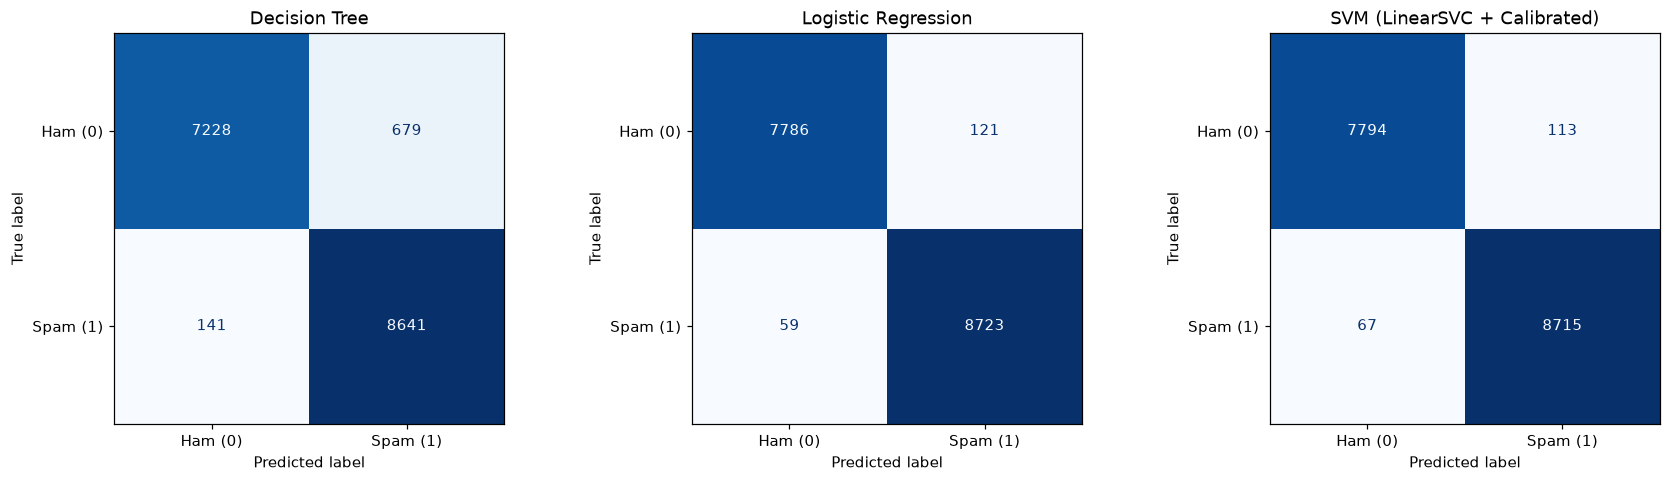

In [4]:
X_test, y_test = load_test_data()
fig, axes = plt.subplots(1, len(MODEL_SPECS), figsize=(16, 4.5))

for ax, spec in zip(axes, MODEL_SPECS):
    with (MODELS_DIR / spec["filename"]).open("rb") as f:
        m = pickle.load(f)
    y_pred = m.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(cm, display_labels=["Ham (0)", "Spam (1)"])
    disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
    ax.set_title(spec["name"])

plt.tight_layout()
plt.show()

## 4. Kết luận

In [5]:
best = metadata["best_metrics"]
print("=============================================")
print(f"MÔ HÌNH CHÍNH ĐƯỢC CHỌN: {metadata['best_model_name']}")
print(f"  - Accuracy        : {best['accuracy']*100:.4f}%")
print(f"  - Precision (Spam): {best['precision_spam']*100:.4f}%")
print(f"  - Recall (Spam)   : {best['recall_spam']*100:.4f}%")
print(f"  - F1-Score (Spam) : {best['f1_spam']*100:.4f}%")
print(f"  - ROC-AUC         : {best['roc_auc']:.4f}")
print(f"  - Số mẫu đoán sai : {best['errors']:,} / {metadata['test_samples']:,}")
print(f"  - Đã lưu tại      : {metadata['best_model_path']}")
print("=============================================")

MÔ HÌNH CHÍNH ĐƯỢC CHỌN: Logistic Regression
  - Accuracy        : 98.9214%
  - Precision (Spam): 98.6318%
  - Recall (Spam)   : 99.3282%
  - F1-Score (Spam) : 98.9788%
  - ROC-AUC         : 0.9989
  - Số mẫu đoán sai : 180 / 16,689
  - Đã lưu tại      : models/best_model.pkl
